In [1]:
pip install gensim

Note: you may need to restart the kernel to use updated packages.


In [30]:
import pandas as pd
import numpy as np
import re
import os
import pickle
import matplotlib.pyplot as plt

import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords


## 1. Load & Clean Data

In [3]:
df = pd.read_csv('/kaggle/input/datasets/mohammad9952/newz-dataset/fake_news_cleaned (1).csv')
df

,Unnamed: 0,text,class
0,0,washington reuters the head of a conservative...,1
1,1,washington reuters transgender people will be...,1
2,2,washington reuters the special counsel invest...,1
3,3,washington reuters trump campaign adviser geo...,1
4,4,seattlewashington reuters president donald tr...,1
...,...,...,...
44262,44262,21st century wire says as 21wire reported earl...,0
44263,44263,21st century wire says it s a familiar theme w...,0
44264,44264,patrick henningsen 21st century wireremember w...,0
44265,44265,21st century wire says al jazeera america will...,0


In [4]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [32]:

print('Shape:', df.shape)
df.isna().sum()


Shape: (38619, 3)


text      0
class     0
tokens    0
dtype: int64

In [33]:
df['class'].value_counts()


class
1    21172
0    17447
Name: count, dtype: int64

In [35]:
df

,text,class,tokens
0,washington reuters the head of a conservative...,1,"[washington, reuters, head, conservative, repu..."
1,washington reuters transgender people will be...,1,"[washington, reuters, transgender, people, all..."
2,washington reuters the special counsel invest...,1,"[washington, reuters, special, counsel, invest..."
3,washington reuters trump campaign adviser geo...,1,"[washington, reuters, trump, campaign, adviser..."
4,seattlewashington reuters president donald tr...,1,"[seattlewashington, reuters, president, donald..."
...,...,...,...
38614,21st century wire says all the world s a stage...,0,"[st, century, wire, says, world, stage, men, w..."
38615,randy johnson 21st century wirethe majority of...,0,"[randy, johnson, st, century, wirethe, majorit..."
38616,tune in to the alternate current radio network...,0,"[tune, alternate, current, radio, network, acr..."
38617,21st century wire says a new front has just op...,0,"[st, century, wire, says, new, front, opened, ..."


### 2. Text Preprocessing

**Important:** The preprocessor returns a **list of tokens** (not a string)This is required by both Word2Vec and the Keras Tokenizer

In [8]:

stop_words = set(stopwords.words('english'))

def preprocessor(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words]
    return tokens

df['tokens'] = df['text'].apply(preprocessor)



In [9]:
# Check token length distribution to choose max_len correctly
token_lengths = df['tokens'].apply(len)
print('Token length stats:')
print(token_lengths.describe())


Token length stats:
count    38619.000000
mean       228.100184
std        178.019875
min          0.000000
25%        123.000000
50%        206.000000
75%        286.000000
max       4841.000000
Name: tokens, dtype: float64


In [40]:
print(f'\n95th percentile: {token_lengths.quantile(0.95)}')
print(f'99th percentile: {token_lengths.quantile(0.99)}')



95th percentile: 509.0
99th percentile: 741.6399999999994


## 3. Train Word2Vec


In [ ]:
from gensim.models import Word2Vec

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix


In [11]:
w2v_model = Word2Vec(window=10,min_count=2,vector_size=100,workers=4,epochs=10)
# window=10 captures semantic relationships in news text
# min_count=2 removes truly rare/noise words
# vector_size=100 — standard for news datasets
# workers=4 — parallel training

In [12]:
w2v_model.build_vocab(df['tokens'])
print(f'Vocabulary size:{len(w2v_model.wv.index_to_key)}')
print(f'Corpus docs: {w2v_model.corpus_count}, Epochs: {w2v_model.epochs}')


Vocabulary size: 85320
Corpus docs: 38619, Epochs: 10


In [13]:
w2v_model.train( df['tokens'], total_examples=w2v_model.corpus_count, epochs=w2v_model.epochs)


(84424217, 88090010)

#(total_words_processed, total_words_expected)

In [14]:

print('\nMost similar to "trump":', w2v_model.wv.most_similar('trump', topn=5))

print(f'Total unique tokens in Word2Vec: {len(w2v_model.wv.index_to_key)}')


Most similar to "trump": [('trumps', 0.7583795189857483), ('trumptrump', 0.5806471109390259), ('bluster', 0.5568354725837708), ('trumpi', 0.5406351685523987), ('presidentelect', 0.5397006273269653)]
Total unique tokens in Word2Vec: 85320


In [42]:
w2v_model.wv.similarity('modi','narendra')

np.float32(0.7905634)

In [43]:
w2v_model.wv.similarity('modi','trump')

np.float32(0.11689342)

In [46]:
w2v_model.wv.similarity('modi','peace')

np.float32(0.12309416)

## 4. Build Embedding Matrix



In [15]:
# oov_token handles unknown words at inference time
tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts(df['tokens'])   
word_index = tokenizer.word_index

print(f'Tokenizer vocab size: {len(word_index)}')
print(f'Word2Vec vocab size:  {len(w2v_model.wv.index_to_key)}')



Tokenizer vocab size: 212261
Word2Vec vocab size:  85320


In [16]:
embedding_dim = 100

embedding_matrix = np.zeros((len(word_index) + 1, embedding_dim))

covered = 0
for word, i in word_index.items():
    if word in w2v_model.wv:
        embedding_matrix[i] = w2v_model.wv[word]
        covered += 1



In [47]:
print(f'\nEmbedding coverage: {covered}/{len(word_index)} words = {covered/len(word_index)*100:.1f}%')
print(f'Words with zero vectors (rare words not in W2V): {len(word_index)-covered}')
print(f'Embedding matrix shape: {embedding_matrix.shape}')


Embedding coverage: 85320/212261 words = 40.2%
Words with zero vectors (rare words not in W2V): 126941
Embedding matrix shape: (212262, 100)


## 5. Prepare Sequences


In [48]:
MAX_LEN = 500

sequences = tokenizer.texts_to_sequences(df['tokens'])
X = pad_sequences(sequences, maxlen=MAX_LEN, padding='pre', truncating='post')
y = df['class'].values

print(f'X shape: {X.shape}')   
print(f'y shape: {y.shape}')
print(f'y distribution: {np.bincount(y)}')

sample_nonzero = np.count_nonzero(X[0])
print(f'Non-zero tokens in sample doc: {sample_nonzero}/{MAX_LEN}')

X shape: (38619, 500)
y shape: (38619,)
y distribution: [17447 21172]
Non-zero tokens in sample doc: 439/500


## 6. Train/Test Split

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y  # stratify preserves class ratio
)


## 7. Build LSTM Architecture


In [51]:
model = Sequential()
# Embedding converts integer indices → dense vectors
# trainable=True allows fine-tuning the Word2Vec vectors during LSTM training
model.add(Embedding(input_dim=len(word_index) + 1,output_dim=embedding_dim,weights=[embedding_matrix],input_length=MAX_LEN,trainable=True))
# Bidirectional LSTM reads text forwards and backwards
model.add(Bidirectional(LSTM(128, dropout=0.3,recurrent_dropout=0.2)))

model.add(Dropout(0.4))

model.add(Dense(1, activation='sigmoid'))

model.build(input_shape=(None, MAX_LEN))

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 500, 100)       │    21,226,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 256)            │       234,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,460,953 (81.87 MB)

 Trainable params: 21,460,953 (81.87 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train with Callbacks

In [21]:
callbacks = [EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)]

history = model.fit(X_train, y_train,batch_size=264,epochs=5,validation_data=(X_test, y_test),callbacks=callbacks)

Epoch 1/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 299s 2s/step - accuracy: 0.9121 - loss: 0.2157 - val_accuracy: 0.9588 - val_loss: 0.1095
Epoch 2/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 286s 2s/step - accuracy: 0.9825 - loss: 0.0551 - val_accuracy: 0.9964 - val_loss: 0.0157
Epoch 3/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 287s 2s/step - accuracy: 0.9950 - loss: 0.0158 - val_accuracy: 0.9987 - val_loss: 0.0062
Epoch 4/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 288s 2s/step - accuracy: 0.9974 - loss: 0.0096 - val_accuracy: 0.9986 - val_loss: 0.0057
Epoch 5/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 290s 2s/step - accuracy: 0.9976 - loss: 0.0086 - val_accuracy: 0.9991 - val_loss: 0.0050


## 9. Evaluate

In [52]:
loss, acc = model.evaluate(X_test, y_test)
print('Test Loss:'loss)
print('Test Accuracy:'acc)


242/242 ━━━━━━━━━━━━━━━━━━━━ 105s 429ms/step - accuracy: 0.4259 - loss: 0.7123
Test Loss: 0.7123173475265503
Test Accuracy: 0.42594510316848755


In [23]:
y_pred = (model.predict(X_test) >= 0.5).astype(int).flatten()

242/242 ━━━━━━━━━━━━━━━━━━━━ 100s 406ms/step

Classification Report:


In [24]:
print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))


              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      3489
        Real       1.00      1.00      1.00      4235

    accuracy                           1.00      7724
   macro avg       1.00      1.00      1.00      7724
weighted avg       1.00      1.00      1.00      7724



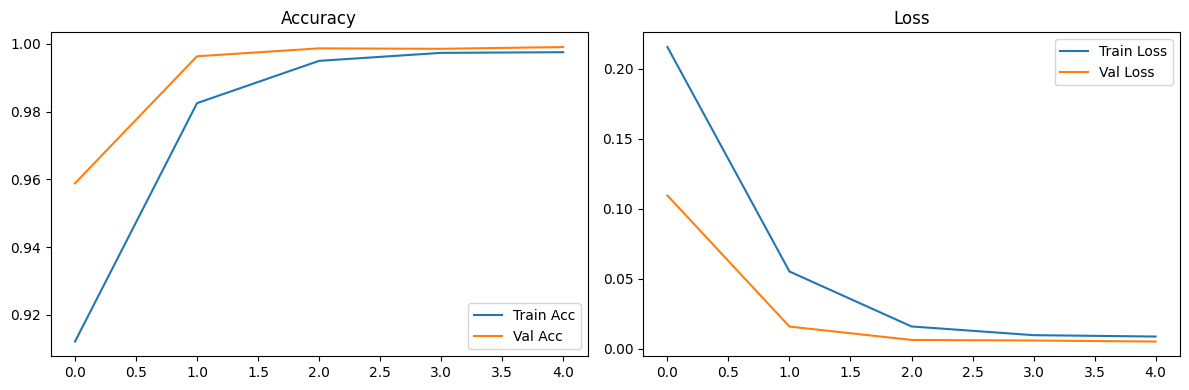

In [25]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['accuracy'], label='Train Acc')
ax1.plot(history.history['val_accuracy'], label='Val Acc')
ax1.set_title('Accuracy'); ax1.legend()
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Loss'); ax2.legend()
plt.tight_layout()
plt.savefig('training_curves.png', dpi=100)
plt.show()

## 10. Save 

In [26]:
model.save('news_classifier.keras')

with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

All artifacts saved.


In [ ]:
with open('stopwords.pkl', 'wb') as f:
    pickle.dump(stop_words, f)

In [ ]:
import json
config = {'MAX_LEN': MAX_LEN, 'embedding_dim': embedding_dim}
with open('config.json', 'w') as f:
    json.dump(config, f)

# Tedsting on real data

In [53]:
def predict_news(text, model, tokenizer, stop_words, max_len=500):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = [w for w in text.split() if w not in stop_words]

    if not tokens:
        print('Warning: No tokens after preprocessing. Input text may be too short or all stopwords.')
        return None

    seq = tokenizer.texts_to_sequences([tokens])
    padded = pad_sequences(seq, maxlen=max_len, padding='pre', truncating='post')

    prob = model.predict(padded, verbose=0)[0][0]
    label = 'Fake' if prob >= 0.5 else 'Real'

    print(f'Probability: {prob} → Predicted: {label}')
    return prob, label


test_texts = [
    """The president signed a new executive order today regarding immigration policy.
    White House officials confirmed the order would take effect immediately and affects
    border controls across multiple states. Congressional leaders from both parties
    responded with statements.""",

    """BREAKING: Scientists discover that drinking bleach cures all diseases.
    The mainstream media is hiding this secret cure from the public.
    Share this before they delete it! The government does not want you to know.""",

    '''India Won't Pay Toll To Pass Through Strait Of Hormuz': Hardeep Puri To NDTV"
    There is some arrangement at play with Iran. They have been good to us. I mean, 
    all sides have been good to us," Union Minister for Petroleum and Natural Gas Hardeep Singh Puri said'''
]

for text in test_texts:
    predict_news(text, model, tokenizer, stop_words, MAX_LEN)

Probability: 0.5522684454917908 → Predicted: Fake
Probability: 0.4917393922805786 → Predicted: Real
Probability: 0.5581681132316589 → Predicted: Fake
